In [20]:
from pathlib import Path
import pandas as pd

In [21]:
data_dir = Path("../data/raw/gov_spend")

In [22]:
files = sorted(data_dir.glob("*.csv"))
assert len(files) >= 6, f"Expected at least 6 CSV files. found {len(files)}"

In [23]:
monthly_frames = []

In [24]:
for file_path in files:
    month = pd.read_csv(file_path, encoding="cp1252")
    month.columns = month.columns.str.strip()   
    
    month = month.rename(columns={
        "Date": "date",
        "Department": "department",
        "Expense Type": "expense_type",
        "Supplier": "supplier",
        "Amount": "amount",
    })
    
    month["date"] = pd.to_datetime(
        month["date"],
        format="mixed",
        dayfirst=True,
        errors="coerce",
    )
    
    amount_in_pounds = pd.to_numeric(
        month["amount"]
        .astype(str)
        .str.replace("£", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="coerce"
    )
    
    month["amount_pence"] = (amount_in_pounds * 100).round().astype("Int64")
    
    monthly_frames.append(
        month[["date", "department", "expense_type", "supplier", "amount_pence"]]
    )

In [25]:
combined = pd.concat(monthly_frames, ignore_index=True)

In [26]:
print("CSV files loaded:", len(files))
print("Combined table shape:", combined.shape)


month_counts = combined.groupby(combined["date"].dt.to_period("M")).size()

display(month_counts)
display(combined.head())
display(combined.dtypes)
display(combined.isna().sum())

CSV files loaded: 6
Combined table shape: (5513, 5)


date
2025-02      48
2025-08      31
2025-09    1138
2025-10    1108
2025-11     952
2025-12    1119
2026-01      18
2026-02    1099
Freq: M, dtype: int64

,date,department,expense_type,supplier,amount_pence
0,2025-12-05,DE,Invoice,Agricarbon UK Limited,19654136
1,2025-12-05,DE,Invoice,Agricarbon UK Limited,6115218
2,2025-12-12,DE,Invoice,Agrosoft Ltd,2400000
3,2025-12-05,DE,Invoice,Barnett Waddingham LLP,2912250
4,2025-12-19,DE,Invoice,Barratt Rental Limited,7353810


date            datetime64[us]
department                 str
expense_type               str
supplier                   str
amount_pence             Int64
dtype: object

date            0
department      0
expense_type    0
supplier        0
amount_pence    0
dtype: int64

In [27]:
for file_path in files:
    raw_month = pd.read_csv(file_path, encoding="cp1252")
    raw_month.columns = raw_month.columns.str.strip()

    parsed_dates = pd.to_datetime(
        raw_month["Date"],
        format="mixed",
        dayfirst=True,
        errors="coerce",
    )

    invalid_date_mask = parsed_dates.isna()
    invalid_count = int(invalid_date_mask.sum())

    print(f"{file_path.name}: {invalid_count} invalid dates out of {len(raw_month)} rows")

    if invalid_count > 0:
        display(
            raw_month.loc[
                invalid_date_mask,
                ["Date", "Department", "Expense Type", "Supplier"],            
            ].head(10)
        )

December_2025.csv: 0 invalid dates out of 1118 rows
February_2026.csv: 0 invalid dates out of 1147 rows
January_2026.csv: 0 invalid dates out of 18 rows
November_2025.csv: 0 invalid dates out of 953 rows
October_2025.csv: 0 invalid dates out of 1108 rows
September_2025.csv: 0 invalid dates out of 1169 rows


In [28]:
amount_summary = combined["amount_pence"].describe()
display(amount_summary)

count              5513.0
mean      38254057.121894
std      402368221.962043
min           -30626900.0
25%             4342153.0
50%             8440315.0
75%            19702625.0
max         14779085480.0
Name: amount_pence, dtype: Float64

In [29]:
amount_mean = combined["amount_pence"].mean()
amount_std = combined["amount_pence"].std()
coefficient_of_variation = amount_std / amount_mean
print(f"Coefficient of variation: {coefficient_of_variation:.3f}")

Coefficient of variation: 10.518


In [30]:
negative_rows = combined.loc[combined["amount_pence"] < 0]
print("Negative transaction count:", len(negative_rows))
display(negative_rows[["date", "department", "expense_type", "supplier", "amount_pence"]].head(10))

Negative transaction count: 22


,date,department,expense_type,supplier,amount_pence
790,2025-12-18,DE,EXP - CAPITAL GRANTS TO LOCAL GOVERNMENT,KINGS LYNN INTERNAL DRAINAGE BOARD,-20000010
915,2025-12-18,DE,EXP - PURCHASE OF GOODS/SERVICES - OTHER - V&P...,SUNBELT RENTALS LTD,-8437666
1178,2026-02-20,DE,Service Charge,BNP PARIBAS REAL ESTATE ( DEFRA),-3379040
1179,2026-02-20,DE,Service Charge,BNP PARIBAS REAL ESTATE ( DEFRA),-3379040
1931,2026-02-05,DE,EXP EU CAPITAL GRANTS TO PTE SECTOR - PERS & N...,JBA BENTLEY LTD,-8450333
2306,2025-11-11,DE,EXP - PURCHASE OF GOODS/SERVICES - ICT OUTSOUR...,IBM UNITED KINGDOM LTD,-9857735
2383,2025-11-19,DE,EXP - CURRENT GRANTS TO LOCAL GOVERNMENT,BLABY DISTRICT COUNCIL,-2714200
2389,2025-11-17,DE,EXP - CAPITAL GRANTS TO LOCAL GOVERNMENT,WILTSHIRE COUNCIL,-18893550
2392,2025-11-05,DE,EXP - CURRENT GRANTS TO LOCAL GOVERNMENT,DARTMOOR NATIONAL PARK AUTHORITY,-30626900
2404,2025-11-03,DE,EXP - CAPITAL GRANTS TO LOCAL GOVERNMENT,DARTMOOR NATIONAL PARK AUTHORITY,-12285800


In [31]:
import matplotlib.pyplot as plt

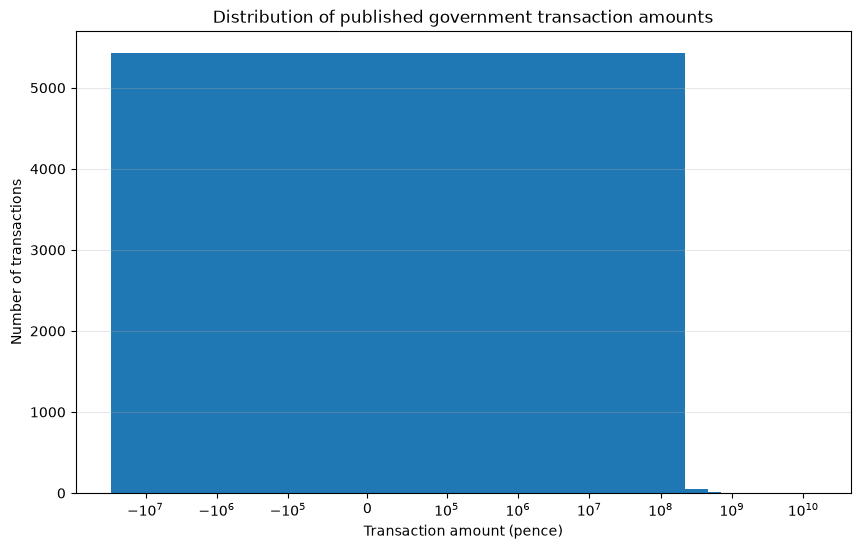

In [32]:
amounts = combined["amount_pence"].astype(float)
plt.figure(figsize=(10, 6))
plt.hist(amounts, bins=60)
plt.xscale("symlog", linthresh=100_000)
plt.title("Distribution of published government transaction amounts")
plt.xlabel("Transaction amount (pence)")
plt.ylabel("Number of transactions")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [33]:
supplier_totals = (
    combined.groupby("supplier")["amount_pence"].sum()
    .sort_values(ascending=False)
    .head(15)
)

display(supplier_totals)

supplier
ENVIRONMENT AGENCY                                      54917965981
SHARED SERVICES CONNECTED LTD                           13914829901
NATURAL ENGLAND                                          9719262371
KIER INTERGRATED SERVICES LTD                            4016714169
BAM NUTTALL LTD                                          3990328623
MINISTRY OF HOUSING COMMUNITIES AND LOCAL GOVERNMENT     3937306400
ISS MEDICLEAN LTD                                        3396327661
VOLKERSTEVIN INFRASTRUCTURE LTD                          3192324600
JACKSON CIVIL ENGINEERING GROUP LTD.                     2702315650
EQUAL EXPERTS UK LTD                                     2383786336
CANAL & RIVER TRUST                                      2360204291
CHESHIRE WEST CHESTER COUNCIL                            2213245521
ROYAL BOTANIC GARDENS KEW                                2156273597
NODE 4 LIMITED (UK)                                      1991001029
CAPGEMINI UK PLC                       

In [34]:
expense_type_counts = (
    combined["expense_type"].value_counts()
    .head(10)
)

display(expense_type_counts)

expense_type
PPE - POA & AUC (OWNED) - COST - O/BAL                                                      587
EXP EU CAPITAL GRANTS TO PTE SECTOR - PERS & NON PROFIT INSTIT'NS SERVING H'HOLD - CWEIY    478
EXP - PURCHASE OF GOODS/SERVICES - RESEARCH & DEVELOPMENT - OTHER OUTSOURCED                381
EXP - CURRENT GRANTS TO LOCAL GOVERNMENT                                                    369
Exp - Purchase Of Goods/Services - Contractors                                              353
EXP - PURCHASE OF GOODS/SERVICES - OTHER PROFESSIONAL SERVICES                              274
EXP - CAPITAL GRANTS TO LOCAL GOVERNMENT                                                    266
EXP - PURCHASE OF GOODS/SERVICES - ICT OUTSOURCING & MAINT/SUPPORT                          255
Exp - Purchase Of Goods/Services - Consultancy                                              226
EXP - PURCHASE OF GOODS/SERVICES - CONSULTANCY - TECHNICAL                                  178
Name: count, dtype: int64

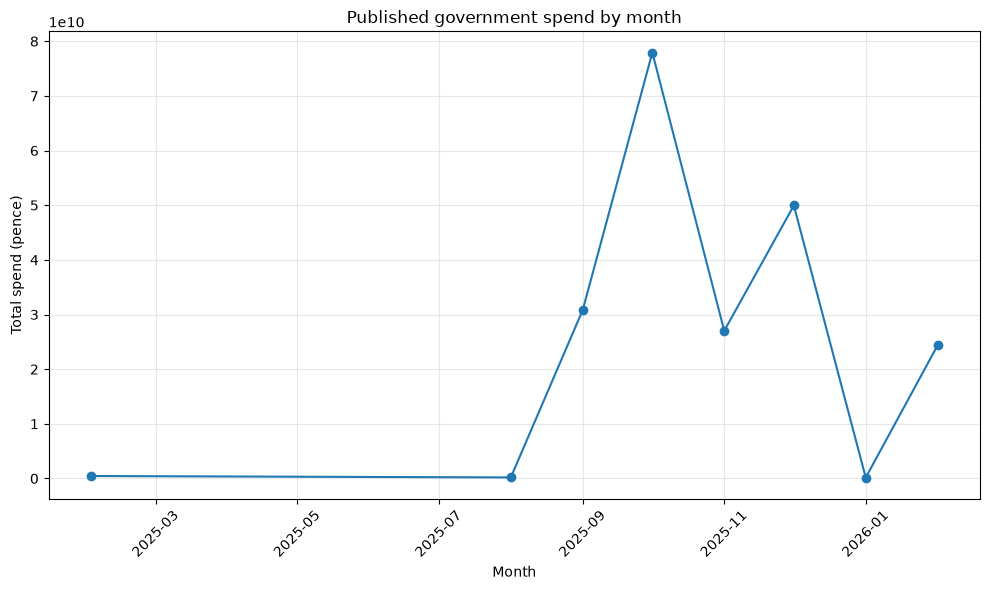

In [40]:
monthly_totals = (
    combined.groupby(combined["date"].dt.to_period("M"))["amount_pence"].sum()
)

monthly_totals.index = monthly_totals.index.to_timestamp()

plt.figure(figsize=(10, 6))
plt.plot(monthly_totals.index, monthly_totals.values, marker="o")
plt.title("Published government spend by month")
plt.xlabel("Month")
plt.ylabel("Total spend (pence)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
synthetic_ledger = pd.read_csv("../data/raw/ledger_v2.csv")

expense_mask = (
    (synthetic_ledger["description"] == "Expense") & (~synthetic_ledger["account_code"].isin([1200, 2000]))
)

synthetic_expense_amounts = synthetic_ledger.loc[expense_mask, "debit_pence"]
real_positive_amounts = combined.loc[combined["amount_pence"] > 0, "amount_pence"]

publication_threshold_pence = 2_500_000
synthetic_comparable = synthetic_expense_amounts.loc[synthetic_expense_amounts >= publication_threshold_pence]
real_comparable = real_positive_amounts.loc[real_positive_amounts >= publication_threshold_pence]



print("Synthetic expense entries:", len(synthetic_expense_amounts))
print("Synthetic expenses above £25,000:", len(synthetic_comparable))
print("Positive real transactions above £25,000:", len(real_comparable))

Synthetic expense entries: 45050
Synthetic expenses above £25,000: 36146
Positive real transactions above £25,000: 5471


In [44]:
def summarize_amounts(amounts):
    amounts_in_pounds = amounts.astype(float) / 100
    mean_amount = amounts_in_pounds.mean()

    return pd.Series({  
        "count": len(amounts_in_pounds),
        "median_pounds": amounts_in_pounds.median(),
        "95th_percentile_pounds": amounts_in_pounds.quantile(0.95),
        "coefficient_of_variation": amounts_in_pounds.std() / mean_amount,
    })


comparison = pd.DataFrame({ 
    "real_positive_published_transactions": summarize_amounts(real_positive_amounts),
    "synthetic_expense_entries": summarize_amounts(synthetic_expense_amounts),
})

display(comparison) 

,real_positive_published_transactions,synthetic_expense_entries
count,5490.000000,45050.000000
median_pounds,84867.495000,84631.815000
95th_percentile_pounds,916157.228500,909955.140500
coefficient_of_variation,10.485986,2.572793


In [45]:
from math import log, sqrt
from statistics import NormalDist

real_median_pounds = float(real_positive_amounts.median()) / 100
real_p95_pounds = float(real_positive_amounts.quantile(0.95)) / 100

candidate_mu = log(real_median_pounds)
normal_p95 = NormalDist().inv_cdf(0.95)
candidate_sigma = log(real_p95_pounds / real_median_pounds) / normal_p95

real_cv = 10.485986
sigma_from_cv = sqrt(log(real_cv**2 + 1))

print(f"Candidate mu from median: {candidate_mu:.2f}")
print(f"Candidate sigma from 95th percentile: {candidate_sigma:.2f}")
print(f"Sigma needed to match real variation: {sigma_from_cv:.2f}")

Candidate mu from median: 11.35
Candidate sigma from 95th percentile: 1.45
Sigma needed to match real variation: 2.17
